<a href="https://colab.research.google.com/github/veekshavkamath-blip/k-means/blob/main/Task_2_2_Clustering(kmeans).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2.2 - Clustering

Steps:
1. Load data, separate the target label, standardise the features
2. K-Means from scratch: choose k (elbow + silhouette), print final centres
3. DBSCAN from scratch: choose eps and min_samples, print number of clusters and noise points
4. PCA plots of both results (DBSCAN noise marked)
5. Compare both against the true labels

The target label is **never used for training**, only for the final plots and evaluation.

## 1. Load data (Google Colab)

The cell below first tries to download the dataset from Google Drive with `gdown` (pre-installed in Colab).
If that fails (e.g. the file is not public), it opens an **upload dialog** so you can choose the dataset file from your computer.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
df = pd.read_csv("seeds_data.csv")
print(df.shape)
df.head()

(210, 8)


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Separate the target from the features, then **standardise** (mean 0, std 1) so no feature dominates the distances.

In [ ]:
y_true = df.iloc[:, -1].to_numpy()
features = df.iloc[:, :-1]

X_raw = features.to_numpy(dtype=float)
feature_names = list(features.columns)

mean, std = X_raw.mean(axis=0), X_raw.std(axis=0)
X = (X_raw - mean) / std

## 2. Helper functions (from scratch)

In [ ]:
def distances(A, B):
    return np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))

D = distances(X, X)
def silhouette(D, labels):
    labels = np.asarray(labels)
    scores = []
    for i in range(len(labels)):
        same = (labels == labels[i])
        same[i] = False
        a = D[i, same].mean()
        b = min(D[i, labels == c].mean()
                for c in np.unique(labels) if c != labels[i])
        scores.append((b - a) / max(a, b))
    return np.mean(scores)

## 3. K-Means from scratch

Steps: pick k starting centres → assign each point to its nearest centre → move each centre to the mean of its points → repeat until the centres stop moving.
We run it several times from different random starts and keep the run with the lowest **inertia** (sum of squared distances to the centres).

In [ ]:
def kmeans(X, k, n_init=10, max_iter=300, seed=SEED):
    rng = np.random.default_rng(seed)
    best_inertia = np.inf
    for _ in range(n_init):
        centres = X[rng.choice(len(X), k, replace=False)]
        for _ in range(max_iter):
            labels = distances(X, centres).argmin(1)
            new_centres = np.array([X[labels == j].mean(0) for j in range(k)])
            if np.allclose(new_centres, centres):
                break
            centres = new_centres
        inertia = ((X - centres[labels]) ** 2).sum()
        if inertia < best_inertia:
            best_inertia, best_centres, best_labels = inertia, centres, labels
    return best_centres, best_labels, best_inertia

centres, labels, inertia = kmeans(X, 3)

### Choosing k

- **Elbow method:** plot inertia vs k and look for the bend where adding more clusters stops helping much.
- **Silhouette score:** higher is better (max 1). The best k is where it peaks.

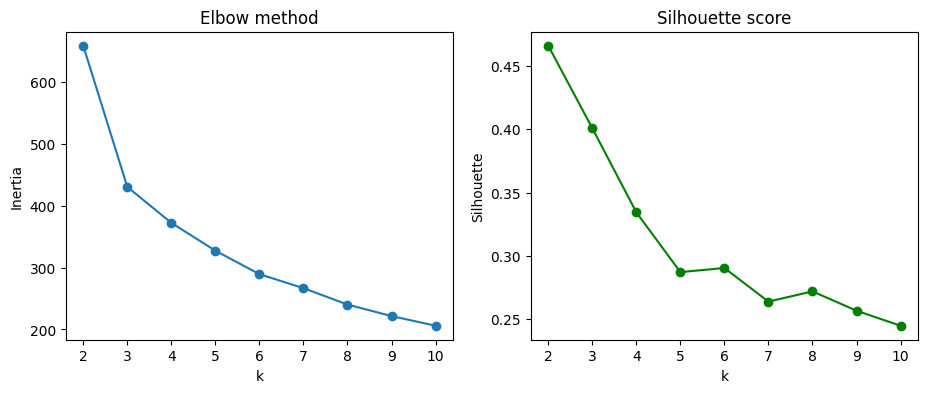

k   variance   silhouette
2 659.17 0.4658
3 430.66 0.4007
4 372.52 0.3344
5 327.47 0.2872
6 289.44 0.2905
7 266.82 0.264
8 240.25 0.2721
9 221.63 0.2568
10 206.0 0.2449


In [ ]:
ks = list(range(2, 11))
inertias = []
sils = []

for k in ks:
    _, labels_k, inertia = kmeans(X, k)
    inertias.append(inertia)
    sils.append(silhouette(D, labels_k))

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(ks, inertias, "o-")
plt.title("Elbow method")
plt.xlabel("k")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(ks, sils, "o-g")
plt.title("Silhouette score")
plt.xlabel("k")
plt.ylabel("Silhouette")

plt.show()

print("k   variance   silhouette")
for k, i, s in zip(ks, inertias, sils):
    print(k, round(i, 2), round(s, 4))

In [ ]:
K_OPT = ks[np.argmax(sils)]
print("Chosen k =", K_OPT)

centres, km_labels, inertia = kmeans(X, K_OPT, n_init=20)
print("Cluster sizes:", np.bincount(km_labels))

print("\nFinal cluster centres (standardised):")
print(pd.DataFrame(centres, columns=feature_names).round(3))

print("\nFinal cluster centres (original units):")
print(pd.DataFrame(centres * std + mean, columns=feature_names).round(3))

Chosen k = 2
Cluster sizes: [133  77]

Final cluster centres (standardised):
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  Feature_7
0     -0.660     -0.665     -0.315     -0.653     -0.618      0.085     -0.666
1      1.141      1.148      0.544      1.129      1.067     -0.147      1.150

Final cluster centres (original units):
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  Feature_7
0     12.931     13.693      0.864      5.340      3.026      3.827      5.082
1     18.159     16.055      0.884      6.127      3.661      3.480      5.972
